<a href="https://colab.research.google.com/github/NabaaNabeeh/NLP-Labs/blob/main/Lab_11_Attention_with_RNN_Solved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [4]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [5]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [7]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)  # fix: input is (batch, seq_len)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #fix: reset gradients each epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

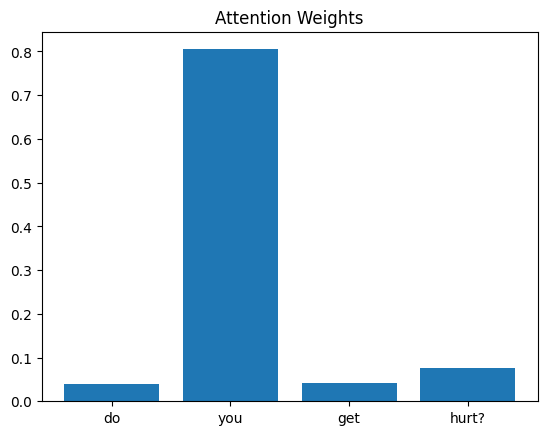

In [9]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


In [10]:
def show_attention(idx, ax):
    words = df["question"][idx].split()
    with torch.no_grad():
        pred, w = model(X[idx:idx+1])
    w = w[0, :len(words)]
    ax.bar(words, w.tolist())
    ax.set_title(f"{df['question'][idx]}\npred={pred.argmax().item()}, true={y[idx].item()}", fontsize=9)
    ax.tick_params(axis="x", rotation=45)
    return words[w.argmax()], w.max().item()

Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

'do you get hurt?' -> top word: you (0.805)
'who is your designer?' -> top word: designer? (0.763)
'what do you like to be called?' -> top word: to (0.353)


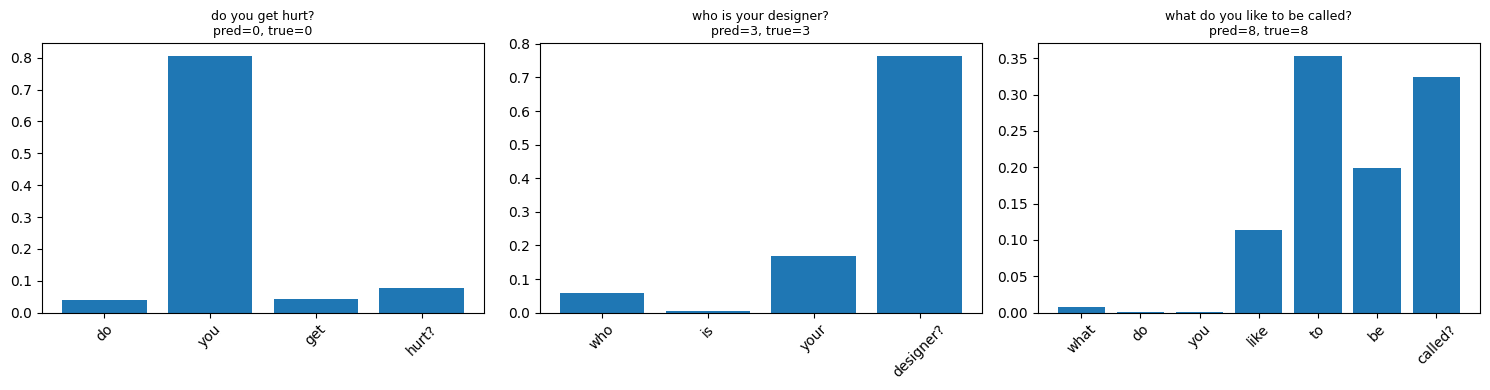

In [11]:
ids = [0, 50, 120]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, ax in zip(ids, axes):
    word, weight = show_attention(i, ax)
    print(f"{df['question'][i]!r} -> top word: {word} ({weight:.3f})")
plt.tight_layout()
plt.show()

**Answer (fill in after running):**

> **Top words:** "do you get hurt?" = you (0.805), "who is your designer?" = designer (0.763), "what do you like to be called?" = to (0.353).
>
> **Observation:** In the second question, the model focused on "designer", the key word. In the third, attention was spread over the phrase "to be called", which carries the meaning. In the first, it focused on "you", a common word, instead of "hurt". All predictions were correct, so the highest attention weight does not always point to the most important word. Attention helps the prediction but does not fully explain it.

*Points to consider:* whether the top word is a content word that separates answer groups or a filler word shared by many questions; in an RNN, the hidden state at a position summarizes all earlier words, so high weight on the last word can reflect the whole question; padding positions also receive softmax weight.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

'do you get hurt?' -> top word: you (0.805)
'do you have fingers?' -> top word: you (0.836)


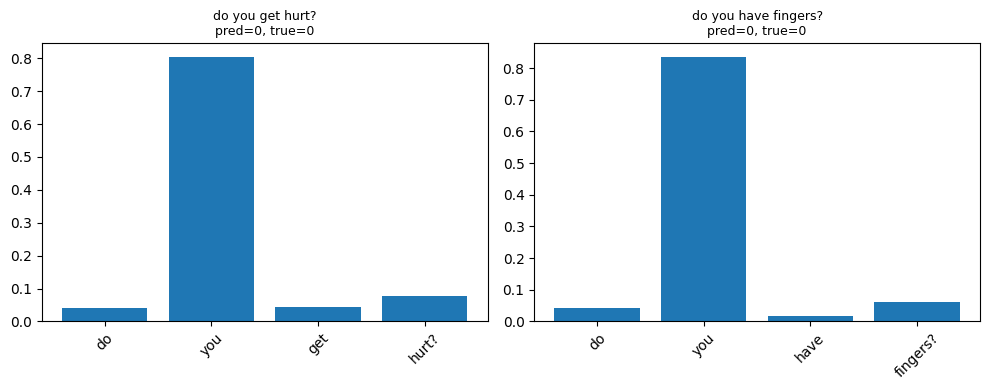

In [12]:
group = 0  # questions in the same answer group share a meaning
pair = df[df["answer_id"] == group].index[:2].tolist()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, ax in zip(pair, axes):
    word, weight = show_attention(i, ax)
    print(f"{df['question'][i]!r} -> top word: {word} ({weight:.3f})")
plt.tight_layout()
plt.show()

**Answer (fill in after running):**

 **Top words:** “do you get hurt?” = you (0.805), “do you have fingers?” = you (0.836).

 **Observation:** The model focused on the same word, “you”, in both questions, while the meaningful words “hurt” and “fingers” got very low weights. Both questions were still classified correctly. This suggests the model relies on the shared structure “do you” rather than the key word, and that attention learns whatever pattern helps the prediction, which may not match human judgment of importance.

*Points to consider:* different words that each carry the key meaning suggest attention selects what is useful for the prediction rather than fixed positions; the same shared word suggests reliance on overlapping wording. Attention weights are learned to help the classifier, so they reflect what helps the prediction, which may not always match human judgment of importance.